# Auditoría de vintages — S2
Simulación, no evidencia empírica ni inferencia causal. Véase informe.md para DGP y literatura.

In [1]:
import csv, json
from pathlib import Path
rows=list(csv.DictReader(Path('results/summary.csv').open()))
for row in rows: print(row)
print(json.loads(Path('results/metadata.json').read_text()))

{'scenario': 'main', 'arm': 'asof_ols', 'mean_seed_rmse': '1.1193890129249477', 'sd_seed_rmse': '0.043791937152422945'}
{'scenario': 'main', 'arm': 'final_no_delay', 'mean_seed_rmse': '0.3040818494208509', 'sd_seed_rmse': '0.012684415984077371'}
{'scenario': 'main', 'arm': 'final_with_delay', 'mean_seed_rmse': '0.9117861494755278', 'sd_seed_rmse': '0.043131041287896035'}
{'scenario': 'main', 'arm': 'ignore_delay', 'mean_seed_rmse': '0.7144298826828954', 'sd_seed_rmse': '0.04370493113088117'}
{'scenario': 'main', 'arm': 'released_mean', 'mean_seed_rmse': '1.16260602369265', 'sd_seed_rmse': '0.09669405087579036'}
{'scenario': 'no_revision', 'arm': 'asof_ols', 'mean_seed_rmse': '0.9117861494755278', 'sd_seed_rmse': '0.043131041287896035'}
{'scenario': 'no_revision', 'arm': 'final_no_delay', 'mean_seed_rmse': '0.3040818494208509', 'sd_seed_rmse': '0.012684415984077371'}
{'scenario': 'no_revision', 'arm': 'final_with_delay', 'mean_seed_rmse': '0.9117861494755278', 'sd_seed_rmse': '0.0431310

La comparación usa el mismo OLS del núcleo compartido. Los brazos retrospectivos son controles positivos de leakage, no competidores desplegables.

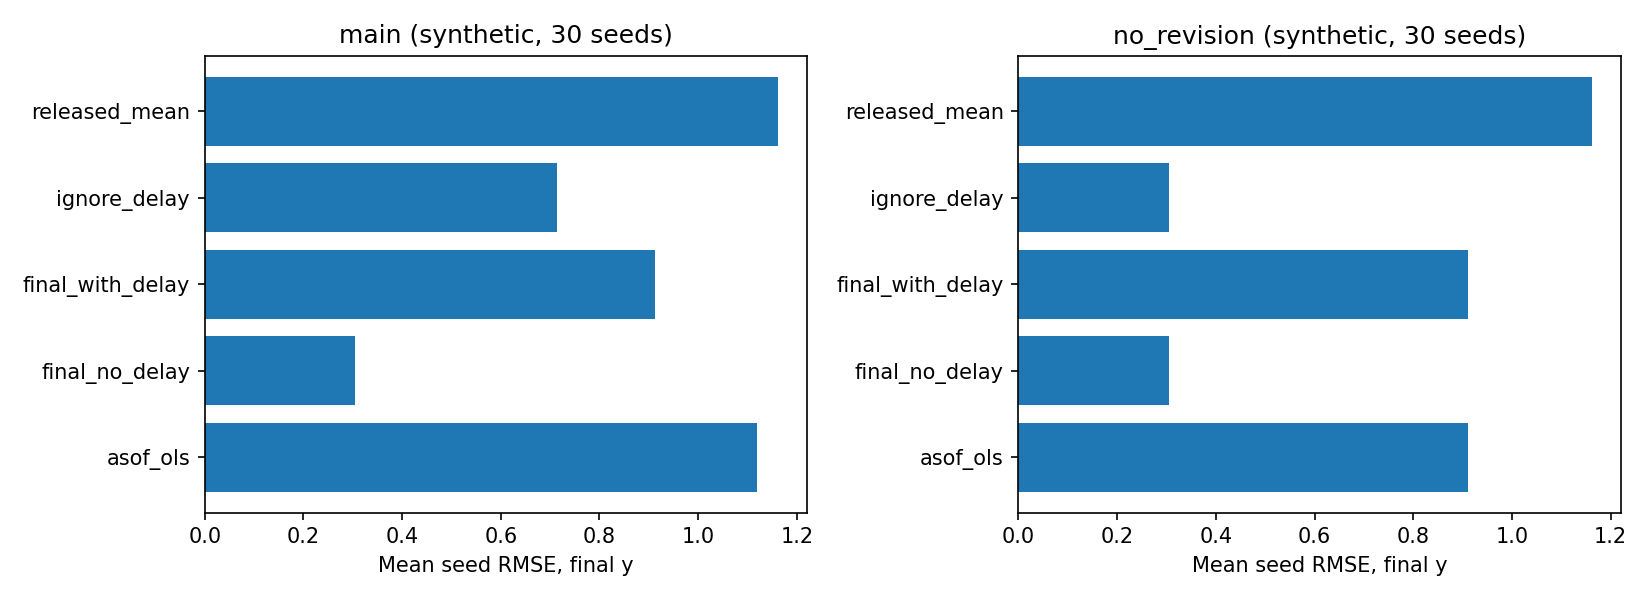

In [2]:
from IPython.display import Image, display
display(Image(filename='results/comparison.png'))

In [3]:
print(Path('results/coverage.txt').read_text())

Name              Stmts   Miss Branch BrPart  Cover   Missing
-------------------------------------------------------------
src/__init__.py       0      0      0      0   100%
src/vintages.py      82      0     26      1    99%   71->61
-------------------------------------------------------------
TOTAL                82      0     26      1    99%



## Desarrollo semanal: mecanismo, sensibilidad y controles

Las celdas nuevas recalculan experimentos específicos. Las salidas históricas anteriores se conservan como evidencia separada y no sustituyen esta ejecución.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


### Información disponible y conjunto de entrenamiento
Un registro debe satisfacer fecha de disponibilidad ≤ origen del pronóstico; que su período económico sea anterior no basta. Se compara el mismo OLS con cortes as-of, datos finales y controles que ignoran retrasos. Los últimos dos son contrafactuales de leakage, no métodos desplegables.

In [5]:
from src.vintages import Config,evaluate,simulate,snapshot
vintage_rows=[]
for delay in [0,1,3]:
    for revision in [0.,.8,1.5]:
        for seed in range(4):
            config=Config(n=110,seed=SEED+seed,delay=delay,revision=revision)
            rows=evaluate(config)
            for arm in sorted({r['arm'] for r in rows}):
                selected=[r for r in rows if r['arm']==arm]
                vintage_rows.append(dict(delay=delay,revision=revision,seed=seed,arm=arm,
                    rmse=np.sqrt(np.mean([r['squared_error'] for r in selected])),
                    future_records=sum(r['violations'] for r in selected)))
vintage_table=pd.DataFrame(vintage_rows)
assert vintage_table.loc[vintage_table.arm=='asof_ols','future_records'].sum()==0
display(vintage_table.groupby(['delay','revision','arm']).agg(rmse_mean=('rmse','mean'),rmse_sd=('rmse','std'),future_records=('future_records','sum')).round(4))

rmse_mean  rmse_sd  future_records
delay revision arm                                                 
0     0.0      asof_ols             0.3210   0.0412               0
               final_no_delay       0.3210   0.0412             200
               final_with_delay     0.3210   0.0412             200
               ignore_delay         0.3210   0.0412               0
               released_mean        1.2213   0.2033               0
      0.8      asof_ols             0.7215   0.0210               0
               final_no_delay       0.3210   0.0412             200
               final_with_delay     0.3210   0.0412             200
               ignore_delay         0.7215   0.0210               0
               released_mean        1.2213   0.2033               0
      1.5      asof_ols             1.2262   0.0263               0
               final_no_delay       0.3210   0.0412             200
               final_with_delay     0.3210   0.0412             200
               ignore_delay         1.2262   0.0263               0
               released_mean        1.2213   0.2033               0
1     0.0      asof_ols             0.9959   0.0955               0
               final_no_delay       0.3210   0.0412             200
               final_with_delay     0.9959   0.0955             200
               ignore_delay         0.3210   0.0412             200
               released_mean        1.2213   0.2033               0
      0.8      asof_ols             1.1758   0.1823               0
               final_no_delay       0.3210   0.0412             200
               final_with_delay     0.9959   0.0955             200
               ignore_delay         0.7215   0.0210             200
               released_mean        1.2213   0.2033               0
      1.5      asof_ols             1.5371   0.2243               0
               final_no_delay       0.3210   0.0412             200
               final_with_delay     0.9959   0.0955             200
               ignore_delay         1.2262   0.0263             200
               released_mean        1.2213   0.2033               0
3     0.0      asof_ols             1.3234   0.0938               0
               final_no_delay       0.3210   0.0412             600
               final_with_delay     1.3234   0.0938             600
               ignore_delay         0.3210   0.0412             200
               released_mean        1.2213   0.2033               0
      0.8      asof_ols             1.4896   0.1070               0
               final_no_delay       0.3210   0.0412             600
               final_with_delay     1.3234   0.0938             600
               ignore_delay         0.7194   0.0196             200
               released_mean        1.2213   0.2033               0
      1.5      asof_ols             1.7812   0.1176               0
               final_no_delay       0.3210   0.0412             600
               final_with_delay     1.3234   0.0938             600
               ignore_delay         1.2035   0.0225             200
               released_mean        1.2213   0.2033               0

### Ejemplo de ledger a una fecha
Se inspeccionan registros elegibles y se muestra cuánto cambia la pertenencia al snapshot. El test de disponibilidad se aplica al registro realmente usado y no sólo al identificador de período.

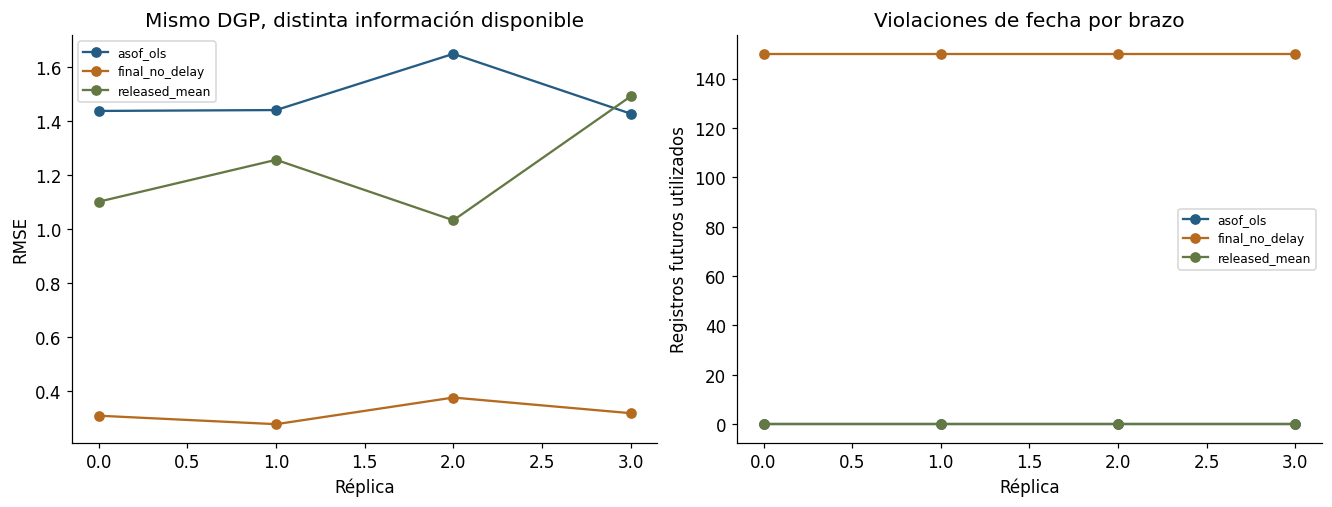

,series,event,available,final,eligible
0,x,62,65,False,True
1,x,62,68,True,False
2,x,63,66,False,False
3,x,63,69,True,False
4,x,64,67,False,False
5,x,64,70,True,False
6,x,65,68,False,False
7,x,65,71,True,False
8,y,62,63,False,True
9,y,62,66,True,False


In [6]:
ledger,_=simulate(Config(n=110,seed=SEED,delay=3,revision=.8));origin=65
asof=snapshot(ledger,origin)
assert all(r.available<=origin for r in asof.values())
recent=sorted([r for r in ledger if 62<=r.event<=65],key=lambda r:(r.series,r.event,r.available))
display(pd.DataFrame([dict(series=r.series,event=r.event,available=r.available,final=r.final,eligible=r.available<=origin) for r in recent]))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for arm,color in [('asof_ols','#245C83'),('final_no_delay','#B56A20'),('released_mean','#637843')]:
    group=vintage_table.query('delay==3 and revision==0.8 and arm==@arm')
    axes[0].plot(group.seed,group.rmse,'o-',label=arm,color=color)
    axes[1].plot(group.seed,group.future_records,'o-',label=arm,color=color)
axes[0].set(xlabel='Réplica',ylabel='RMSE',title='Mismo DGP, distinta información disponible')
axes[1].set(xlabel='Réplica',ylabel='Registros futuros utilizados',title='Violaciones de fecha por brazo')
for ax in axes:ax.legend(fontsize=8)
plt.show()

### Lectura crítica
Los brazos con información final pueden mejorar error por información inexistente en origen. La ausencia de violaciones es necesaria para una evaluación desplegable, pero no garantiza un buen modelo. Cuatro semillas por celda permiten detectar el mecanismo, no estimar un ranking de modelos con alta precisión; se informa dispersión y se mantiene la media liberada como baseline.